In [218]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [219]:
df=pd.read_csv('manglish_combined_dataset.csv')
df

,text,category
0,Tovi 🥰 Best Wishes From #Kunjikka Fans,not-malayalam
1,Urutty koll .nallavanaaya unniyaya saiju kuru...,unknown_state
2,Pls support me pls My channel subscribe...,not-malayalam
3,Kalki super hit akum enn Bonny parayan paranju,Positive
4,Ettane kaanan vendi vannavar undo Podunge in...,unknown_state
...,...,...
16633,sneham varumbo manassil varunna ishdamulla per...,Positive
16634,@MohanlalMFC @PMOIndia @CMOKerala @vijayanpina...,Negative
16635,"kuzhichchumoodiyenn svayamahankarichcha, bhoot...",Negative
16636,ith kelkunthorum. ee paattinodulla ishttam koo...,Positive


In [220]:
df.shape

(16638, 2)

In [221]:
df.drop_duplicates(inplace=True)

In [222]:
df['category'] = df['category'].str.strip()

In [223]:
df.drop(df.index[df['category'] == 'not-malayalam'], axis=0, inplace=True)
df.drop(df.index[df['category'] == 'unknown_state'], axis=0, inplace=True)

In [245]:
df['category'].value_counts()

category
Positive          4628
Negative          2661
Mixed_feelings     582
Name: count, dtype: int64

In [242]:
x=df['category'].value_counts().index
y=df['category'].value_counts().values

<BarContainer object of 3 artists>

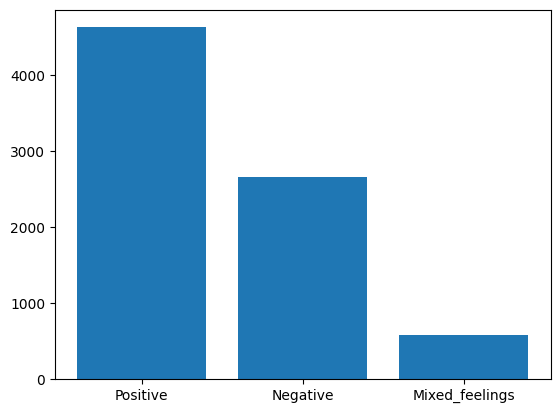

In [244]:
import matplotlib.pyplot as plt
plt.bar(x,y)

In [225]:
# Remove empty text
df = df.dropna(subset=['text', 'category'])
df = df[df['text'].str.strip() != '']

In [226]:
df

,text,category
3,Kalki super hit akum enn Bonny parayan paranju,Positive
6,Become an arjun asokaN fan. .. padam kalakki,Positive
7,Koora padam,Negative
11,Poli padam njn ella mammooty movies kanarundu...,Negative
12,Padathinte peru sheriyalla yenth unda oru ver...,Negative
...,...,...
16633,sneham varumbo manassil varunna ishdamulla per...,Positive
16634,@MohanlalMFC @PMOIndia @CMOKerala @vijayanpina...,Negative
16635,"kuzhichchumoodiyenn svayamahankarichcha, bhoot...",Negative
16636,ith kelkunthorum. ee paattinodulla ishttam koo...,Positive


In [227]:
df.reset_index(drop=True, inplace=True)

In [228]:
df['category'].value_counts()

category
Positive          4628
Negative          2661
Mixed_feelings     582
Name: count, dtype: int64

In [229]:
df['text']=df['text'].apply(lambda x:x.lower())
df['text']

0          kalki super hit akum enn bonny parayan paranju
1            become an arjun asokan fan. .. padam kalakki
2                                             koora padam
3        poli padam njn ella mammooty movies kanarundu...
4        padathinte peru sheriyalla yenth unda oru ver...
                              ...                        
7866    sneham varumbo manassil varunna ishdamulla per...
7867    @mohanlalmfc @pmoindia @cmokerala @vijayanpina...
7868    kuzhichchumoodiyenn svayamahankarichcha, bhoot...
7869    ith kelkunthorum. ee paattinodulla ishttam koo...
7870    nalla sinima. saspens thrillar. kunchaakko bob...
Name: text, Length: 7871, dtype: str

In [230]:
# df["text_key"] = df["text"].str.split().str.join(" ")
# df = df.drop_duplicates(subset="text_key").reset_index(drop=True)

X = df["text"].astype(str)
y = df["category"]

In [231]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=7,
    stratify=y
)

In [232]:
features = FeatureUnion([
    ('word', TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),

    ('char', TfidfVectorizer(
        analyzer='char',
        ngram_range=(2, 5),
        min_df=2,
        sublinear_tf=True
    ))
])

In [233]:
model = Pipeline([
    ('features', features),
    ("classifier", LinearSVC(C=0.25, class_weight="balanced", random_state=98))
])

In [234]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Mixed_feelings','Negative','Positive']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word', ...), ('char', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


In [235]:
y_pred = model.predict(X_test)

In [236]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8914285714285715


In [237]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
                precision    recall  f1-score   support

Mixed_feelings       0.81      0.68      0.74       116
      Negative       0.87      0.89      0.88       533
      Positive       0.92      0.92      0.92       926

      accuracy                           0.89      1575
     macro avg       0.86      0.83      0.84      1575
  weighted avg       0.89      0.89      0.89      1575



In [238]:
y_pred = model.predict(["padam valare shokam ann"])
y_pred

array(['Negative'], dtype=object)

In [239]:
import joblib

joblib.dump(model, 'manglish_model.pkl')

['manglish_model.pkl']